In [1]:
# Install dependensi tambahan
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm>=1.0.0'])
print('✅ timm siap')

✅ timm siap


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print('✅ Google Drive terpasang')

Mounted at /content/drive
✅ Google Drive terpasang


In [3]:
# Semua import dikumpulkan di satu cell
import copy
import importlib.util
import math
import os
import platform
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import timm
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from timm.optim import param_groups_layer_decay
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

print('✅ Semua library berhasil diimport')
print(f'   Python  : {platform.python_version()}')
print(f'   PyTorch : {torch.__version__}')
print(f'   timm    : {timm.__version__}')

✅ Semua library berhasil diimport
   Python  : 3.13.16
   PyTorch : 2.11.0+cu130
   timm    : 1.0.30


In [4]:
# Cek ketersediaan GPU
print('=' * 50)
print(f'  CUDA tersedia : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'  GPU           : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM          : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('  ⚠️  Aktifkan GPU: Runtime → Change runtime type → T4 GPU')
print('=' * 50)

  CUDA tersedia : True
  GPU           : Tesla T4
  VRAM          : 15.6 GB


In [5]:
# CONFIG — semua konstanta di satu cell; sesuaikan path sebelum menjalankan

# ── Path ──────────────────────────────────────────────────────────────────
DRIVE_ROOT     = '/content/drive/MyDrive'
DATASET_ROOT   = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'train')
MY_TRAIN_DIR   = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'my_train')
MY_VAL_DIR     = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'my_val')
CKPT_DIR       = os.path.join(DRIVE_ROOT, 'checkpoints_nb09')  # Drive langsung
SUBMISSION_DIR = '/content/submission_nb09'

# ── Dataset ───────────────────────────────────────────────────────────────
CLASSES     = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
NUM_CLASSES = len(CLASSES)
VAL_FRAC    = 0.15
SEED        = 42

# ── 4 Model NB09: Base × 2 + Small × 2, ConvNeXt + Swin ──────────────────
# Diversity 3 dimensi: arsitektur (CNN vs Attention) + ukuran (Base vs Small) + resep
MODEL_CONFIGS = [
    {
        'tag' : 'm1_convnext_base_std',
        'name': 'convnext_base.fb_in22k_ft_in1k',
        'llrd': False,
        'drop': 0.1,
    },
    {
        'tag' : 'm2_convnext_small_llrd',
        'name': 'convnext_small.fb_in22k_ft_in1k',
        'llrd': True,
        'drop': 0.2,
    },
    {
        'tag' : 'm3_swin_base_std',
        'name': 'swin_base_patch4_window7_224.ms_in22k_ft_in1k',
        'llrd': False,
        'drop': 0.1,
    },
    {
        'tag' : 'm4_swin_small_llrd',
        'name': 'swin_small_patch4_window7_224.ms_in22k_ft_in1k',
        'llrd': True,
        'drop': 0.2,
    },
]

# ── Input ─────────────────────────────────────────────────────────────────
IMG_SIZE      = 224
RESIZE_SIZE   = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── DataLoader ────────────────────────────────────────────────────────────
BATCH_SIZE  = 32
GRAD_ACCUM  = 2       # batch efektif = 64
NUM_WORKERS = 2

# ── Phase 1: head saja ────────────────────────────────────────────────────
P1_EPOCHS  = 3
P1_LR_HEAD = 1e-3

# ── Phase 2: full fine-tune ───────────────────────────────────────────────
P2_EPOCHS      = 30    # lebih panjang dari NB07 (20) dan NB08 (25)
P2_LR_BACKBONE = 1e-4
P2_LR_HEAD     = 1e-3
WEIGHT_DECAY   = 0.05
WARMUP_EPOCHS  = 1
LLRD_DECAY     = 0.85

# ── Regularisasi ──────────────────────────────────────────────────────────
LABEL_SMOOTH = 0.1
EMA_DECAY    = 0.995
MIXUP_ALPHA  = 0.8
CUTMIX_ALPHA = 1.0
MIXUP_PROB   = 0.5

# ── Seed & device ─────────────────────────────────────────────────────────
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(CKPT_DIR,       exist_ok=True)
os.makedirs(SUBMISSION_DIR, exist_ok=True)

print(f'Device        : {DEVICE}')
print(f'Batch efektif : {BATCH_SIZE * GRAD_ACCUM}')
print(f'Phase 2       : {P2_EPOCHS} epoch')
print(f'CKPT dir      : {CKPT_DIR}')
print()
print('4 model yang akan dilatih:')
for cfg in MODEL_CONFIGS:
    resep = 'LLRD' if cfg['llrd'] else 'Standard'
    print(f'  {cfg["tag"]:<28} {cfg["name"]}  [{resep}, drop={cfg["drop"]}]')

Device        : cuda
Batch efektif : 64
Phase 2       : 30 epoch
CKPT dir      : /content/drive/MyDrive/checkpoints_nb09

4 model yang akan dilatih:
  m1_convnext_base_std         convnext_base.fb_in22k_ft_in1k  [Standard, drop=0.1]
  m2_convnext_small_llrd       convnext_small.fb_in22k_ft_in1k  [LLRD, drop=0.2]
  m3_swin_base_std             swin_base_patch4_window7_224.ms_in22k_ft_in1k  [Standard, drop=0.1]
  m4_swin_small_llrd           swin_small_patch4_window7_224.ms_in22k_ft_in1k  [LLRD, drop=0.2]


In [6]:
# Gunakan split dari Drive (NB03) jika ada, atau buat split baru — self-contained
if os.path.isdir(MY_TRAIN_DIR) and os.path.isdir(MY_VAL_DIR):
    TRAIN_DIR = MY_TRAIN_DIR
    VAL_DIR   = MY_VAL_DIR
    print('✅ Split dari Drive dipakai langsung')
    print(f'   TRAIN_DIR : {TRAIN_DIR}')
    print(f'   VAL_DIR   : {VAL_DIR}')
else:
    TRAIN_DIR = '/content/my_train'
    VAL_DIR   = '/content/my_val'
    print('⚠️  Split belum ada — membuat split baru ...')
    for d in [TRAIN_DIR, VAL_DIR]:
        os.makedirs(d, exist_ok=True)
        for cls in CLASSES:
            os.makedirs(os.path.join(d, cls), exist_ok=True)
    for cls in CLASSES:
        src  = os.path.join(DATASET_ROOT, cls)
        imgs = sorted(os.listdir(src))
        tr, vl = train_test_split(imgs, test_size=VAL_FRAC, random_state=SEED)
        for f in tr:
            shutil.copy2(os.path.join(src, f), os.path.join(TRAIN_DIR, cls, f))
        for f in vl:
            shutil.copy2(os.path.join(src, f), os.path.join(VAL_DIR, cls, f))
    print(f'✅ Split selesai (seed={SEED}, val={VAL_FRAC:.0%})')

print(f'\n{"Kelas":<22} {"train":>8} {"val":>6}')
print('-' * 38)
total_tr = total_vl = 0
for cls in CLASSES:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    n_vl = len(os.listdir(os.path.join(VAL_DIR,   cls)))
    total_tr += n_tr
    total_vl += n_vl
    print(f'  {cls:<20} {n_tr:>8} {n_vl:>6}')
print('-' * 38)
print(f'  {"Total":<20} {total_tr:>8} {total_vl:>6}')

✅ Split dari Drive dipakai langsung
   TRAIN_DIR : /content/drive/MyDrive/dataset_sampah/my_train
   VAL_DIR   : /content/drive/MyDrive/dataset_sampah/my_val

Kelas                     train    val
--------------------------------------
  botol_plastik             445     78
  gelas_plastik             443     78
  kertas_kardus             311     54
  saset_kemasan             573    100
  styrofoam                 571    100
--------------------------------------
  Total                    2343    410


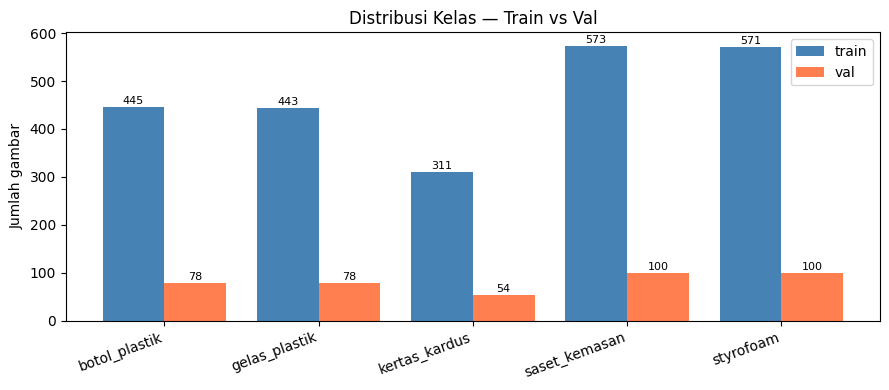

In [7]:
# Visualisasi distribusi kelas train vs val
counts_tr = [len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in CLASSES]
counts_vl = [len(os.listdir(os.path.join(VAL_DIR,   c))) for c in CLASSES]
x = range(NUM_CLASSES)

fig, ax = plt.subplots(figsize=(9, 4))
b1 = ax.bar([i - 0.2 for i in x], counts_tr, 0.4, label='train', color='steelblue')
b2 = ax.bar([i + 0.2 for i in x], counts_vl, 0.4, label='val',   color='coral')
ax.set_xticks(list(x))
ax.set_xticklabels(CLASSES, rotation=20, ha='right')
ax.set_ylabel('Jumlah gambar')
ax.set_title('Distribusi Kelas — Train vs Val')
ax.legend()
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Transform train (augmentasi kuat) dan val (deterministik, identik dengan submission)
def get_train_transform():
    """RandomResizedCrop + ColorJitter + TrivialAugmentWide + RandomErasing."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
        transforms.TrivialAugmentWide(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.35, scale=(0.02, 0.2)),
    ])


def get_val_transform():
    """Resize(256) + CenterCrop(224) — sama dengan get_transform() di submission."""
    return transforms.Compose([
        transforms.Resize(RESIZE_SIZE),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])


train_tf = get_train_transform()
val_tf   = get_val_transform()
print(f'✅ Train : {len(train_tf.transforms)} transform')
print(f'   Val   : {len(val_tf.transforms)} transform')

✅ Train : 7 transform
   Val   : 4 transform


In [9]:
# Dataset dan DataLoader — shuffle biasa, tanpa WeightedRandomSampler
train_ds = ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds   = ImageFolder(VAL_DIR,   transform=val_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f'Train : {len(train_ds)} gambar | {len(train_loader)} batch')
print(f'Val   : {len(val_ds)} gambar | {len(val_loader)} batch')
print(f'Kelas : {train_ds.classes}')

Train : 2343 gambar | 74 batch
Val   : 410 gambar | 13 batch
Kelas : ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']


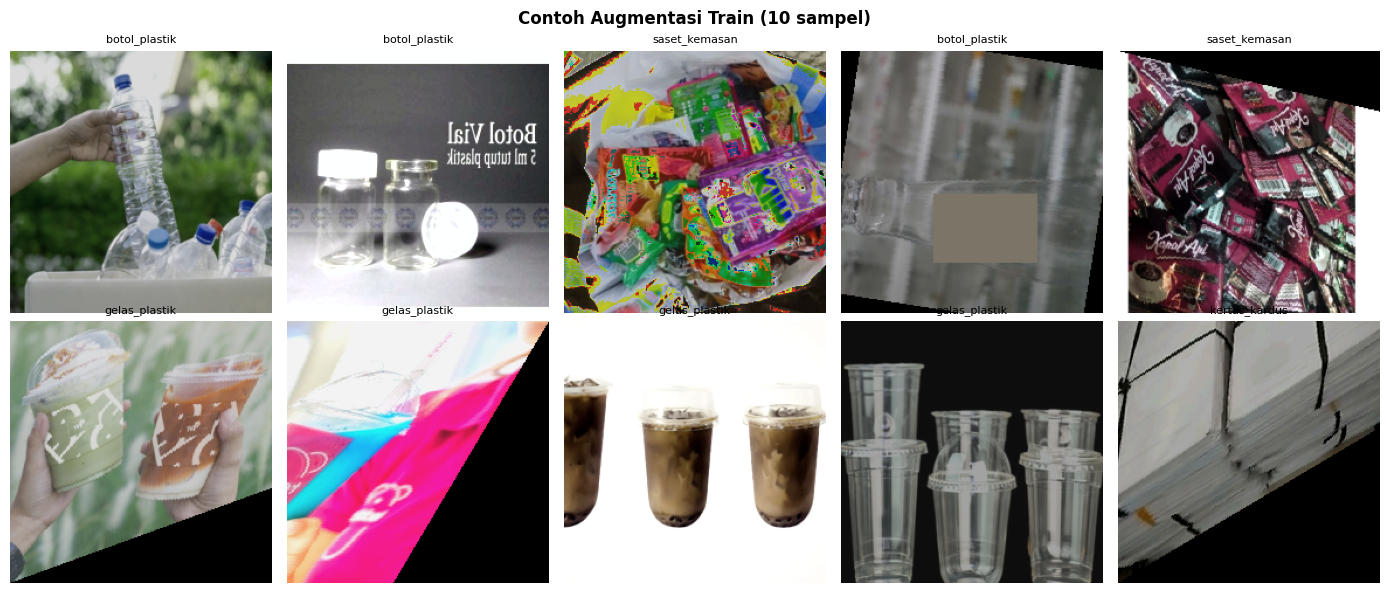

In [10]:
# Visualisasi 10 contoh augmentasi train
MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD_T  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    """Denormalisasi tensor gambar untuk ditampilkan."""
    return (t * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()


imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Contoh Augmentasi Train (10 sampel)', fontsize=12, fontweight='bold')
for ax, img, lbl in zip(axes.flat, imgs[:10], labels[:10]):
    ax.imshow(denorm(img))
    ax.set_title(train_ds.classes[lbl], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
# EMA, Mixup/CutMix, dan soft cross-entropy dengan label smoothing

class EMA:
    """Exponential Moving Average bobot model — checkpoint lebih stabil."""
    def __init__(self, model, decay=EMA_DECAY):
        self.decay  = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for s, m in zip(self.shadow.parameters(), model.parameters()):
            s.data = self.decay * s.data + (1 - self.decay) * m.data

    def model(self):
        return self.shadow


def rand_bbox(size, lam):
    """Koordinat kotak acak untuk CutMix."""
    W, H   = size[2], size[3]
    cut    = math.sqrt(1 - lam)
    cw, ch = int(W * cut), int(H * cut)
    cx, cy = np.random.randint(W), np.random.randint(H)
    return (max(0, cx - cw // 2), max(0, cy - ch // 2),
            min(W, cx + cw // 2), min(H, cy + ch // 2))


def get_batch_mix(imgs, labels, n_cls=NUM_CLASSES):
    """Terapkan Mixup atau CutMix secara acak; kembalikan (imgs, soft_labels)."""
    if np.random.rand() > MIXUP_PROB:
        oh = torch.zeros(len(labels), n_cls, device=imgs.device)
        return imgs, oh.scatter_(1, labels.unsqueeze(1), 1)
    idx = torch.randperm(len(imgs), device=imgs.device)
    if np.random.rand() < 0.5:          # Mixup
        lam  = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)
        imgs = lam * imgs + (1 - lam) * imgs[idx]
    else:                               # CutMix
        lam             = np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
        x1, y1, x2, y2 = rand_bbox(imgs.size(), lam)
        imgs[:, :, x1:x2, y1:y2] = imgs[idx, :, x1:x2, y1:y2]
        lam = 1 - (x2 - x1) * (y2 - y1) / (imgs.size(2) * imgs.size(3))
    oh_a = torch.zeros(len(labels), n_cls, device=imgs.device).scatter_(1, labels.unsqueeze(1), 1)
    oh_b = torch.zeros(len(labels), n_cls, device=imgs.device).scatter_(1, labels[idx].unsqueeze(1), 1)
    return imgs, lam * oh_a + (1 - lam) * oh_b


def soft_ce_loss(logits, soft_labels, smooth=LABEL_SMOOTH):
    """Cross-entropy dengan soft targets dan label smoothing."""
    n  = logits.size(1)
    sl = soft_labels * (1 - smooth) + smooth / n
    return -(sl * nn.functional.log_softmax(logits, dim=1)).sum(dim=1).mean()


print('✅ EMA, Mixup/CutMix, soft_ce_loss siap')

✅ EMA, Mixup/CutMix, soft_ce_loss siap


In [12]:
# Loop train dan evaluasi satu epoch

def train_epoch(model, loader, optimizer, scaler, ema=None, scheduler=None, accum=GRAD_ACCUM):
    """Train satu epoch: AMP + gradient accumulation + clip norm + EMA opsional."""
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()
    for step, (imgs, labels) in enumerate(loader):
        imgs, labels   = imgs.to(DEVICE), labels.to(DEVICE)
        imgs, soft_lbl = get_batch_mix(imgs, labels)
        with torch.autocast(device_type='cuda', dtype=torch.float16,
                            enabled=torch.cuda.is_available()):
            loss = soft_ce_loss(model(imgs), soft_lbl) / accum
        scaler.scale(loss).backward()
        if (step + 1) % accum == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            if ema:       ema.update(model)
            if scheduler: scheduler.step()
        total_loss += loss.item() * accum
    return total_loss / len(loader)


@torch.no_grad()
def eval_epoch(model, loader):
    """Hitung Macro-F1 dan akurasi pada satu DataLoader."""
    model.eval()
    preds, truths = [], []
    for imgs, labels in loader:
        preds.extend(model(imgs.to(DEVICE)).argmax(1).cpu().tolist())
        truths.extend(labels.tolist())
    f1  = f1_score(truths, preds, average='macro', zero_division=0)
    acc = sum(p == t for p, t in zip(preds, truths)) / len(truths)
    return f1, acc


print('✅ train_epoch, eval_epoch siap')

✅ train_epoch, eval_epoch siap


In [13]:
# Build model, freeze/unfreeze backbone, optimizer standar & LLRD, scheduler

def _is_head(name):
    # Cek level pertama nama parameter saja — hindari match mlp.fc1/fc2 di dalam blok
    return name.split('.')[0] in ('head', 'classifier')


def build_model(cfg):
    """Buat model timm pretrained sesuai config."""
    model = timm.create_model(
        cfg['name'], pretrained=True,
        num_classes=NUM_CLASSES, drop_path_rate=cfg['drop']
    )
    model = model.to(DEVICE)
    if torch.cuda.is_available():
        model = model.to(memory_format=torch.channels_last)
    n = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  {cfg["name"]}  ({n:.1f}M param, drop_path={cfg["drop"]})')
    return model


def freeze_backbone(model):
    """Bekukan semua layer kecuali head classifier."""
    for name, p in model.named_parameters():
        p.requires_grad_(_is_head(name))
    n = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f'    Trainable: {n:.4f}M (head saja)')


def unfreeze_all(model):
    """Aktifkan semua parameter untuk full fine-tuning."""
    for p in model.parameters():
        p.requires_grad_(True)


def make_optimizer_standard(model):
    """AdamW: backbone LR=1e-4, head LR=1e-3."""
    head_p     = [p for n, p in model.named_parameters() if _is_head(n) and p.requires_grad]
    backbone_p = [p for n, p in model.named_parameters() if not _is_head(n) and p.requires_grad]
    return torch.optim.AdamW(
        [{'params': backbone_p, 'lr': P2_LR_BACKBONE},
         {'params': head_p,     'lr': P2_LR_HEAD}],
        weight_decay=WEIGHT_DECAY
    )


def make_optimizer_llrd(model, decay=LLRD_DECAY, base_lr=P2_LR_BACKBONE):
    """AdamW dengan Layer-wise LR Decay via timm; fallback manual."""
    try:
        groups = param_groups_layer_decay(model, weight_decay=WEIGHT_DECAY, layer_decay=decay)
        for g in groups:
            g['lr'] = g.get('lr_scale', 1.0) * base_lr
        opt = torch.optim.AdamW(groups, lr=base_lr)
        print(f'    LLRD via timm — {len(groups)} param groups, decay={decay}')
    except Exception:
        named  = list(model.named_parameters())
        groups = []
        for i, (name, p) in enumerate(named):
            if not p.requires_grad: continue
            lr_i = base_lr * (decay ** (len(named) - i - 1))
            wd   = 0.0 if ('bias' in name or 'norm' in name) else WEIGHT_DECAY
            groups.append({'params': [p], 'lr': lr_i, 'weight_decay': wd})
        opt = torch.optim.AdamW(groups)
        print(f'    LLRD manual — {len(groups)} param groups')
    return opt


def make_scheduler(optimizer, total_steps, warmup_steps):
    """Linear warmup + cosine decay per langkah optimizer."""
    def lr_lambda(step):
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.0, 0.5 * (1 + math.cos(math.pi * prog)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


print('✅ build_model, optimizer standar & LLRD, scheduler siap')

✅ build_model, optimizer standar & LLRD, scheduler siap


In [14]:
# Fungsi training lengkap (Phase 1 + Phase 2) dan plotting kurva

def train_full(cfg):
    """Latih satu model dua fase; checkpoint terbaik disimpan ke Drive."""
    tag       = cfg['tag']
    use_llrd  = cfg['llrd']
    resep     = 'LLRD' if use_llrd else 'Standard'
    best_path = os.path.join(CKPT_DIR, f'{tag}_best.pth')
    history   = {'loss': [], 'f1': [], 'f1_ema': []}
    best_f1   = 0.0

    print(f'\n{"="*62}')
    print(f'  {tag}  |  {resep}  |  drop_path={cfg["drop"]}')
    print(f'{"="*62}')

    model  = build_model(cfg)
    scaler = torch.GradScaler(enabled=torch.cuda.is_available())
    ema    = EMA(model)

    # ── Phase 1: head saja ────────────────────────────────────────────────
    print(f'\n  Phase 1 — head only ({P1_EPOCHS} epoch, LR={P1_LR_HEAD})')
    freeze_backbone(model)
    opt1   = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=P1_LR_HEAD, weight_decay=WEIGHT_DECAY
    )
    sched1 = make_scheduler(opt1, P1_EPOCHS * len(train_loader), warmup_steps=0)
    for ep in range(1, P1_EPOCHS + 1):
        loss      = train_epoch(model, train_loader, opt1, scaler, ema=ema, scheduler=sched1)
        f1, _     = eval_epoch(model, val_loader)
        f1_ema, _ = eval_epoch(ema.model(), val_loader)
        history['loss'].append(loss)
        history['f1'].append(f1)
        history['f1_ema'].append(f1_ema)
        print(f'  Ep {ep:02}/{P1_EPOCHS} | loss {loss:.4f} | F1 {f1:.4f} | F1-EMA {f1_ema:.4f}')

    # ── Phase 2: semua layer ──────────────────────────────────────────────
    print(f'\n  Phase 2 — full fine-tune ({P2_EPOCHS} epoch, {resep})')
    unfreeze_all(model)
    opt2   = make_optimizer_llrd(model) if use_llrd else make_optimizer_standard(model)
    sched2 = make_scheduler(
        opt2,
        total_steps  = P2_EPOCHS * len(train_loader),
        warmup_steps = WARMUP_EPOCHS * len(train_loader)
    )
    for ep in range(1, P2_EPOCHS + 1):
        loss      = train_epoch(model, train_loader, opt2, scaler, ema=ema, scheduler=sched2)
        f1, _     = eval_epoch(model, val_loader)
        f1_ema, _ = eval_epoch(ema.model(), val_loader)
        cur       = max(f1, f1_ema)
        if cur > best_f1:
            best_f1 = cur
            torch.save((ema.model() if f1_ema >= f1 else model).state_dict(), best_path)
        history['loss'].append(loss)
        history['f1'].append(f1)
        history['f1_ema'].append(f1_ema)
        mark = ' ✓' if cur == best_f1 else ''
        print(f'  Ep {ep:02}/{P2_EPOCHS} | loss {loss:.4f} | F1 {f1:.4f} | '
              f'F1-EMA {f1_ema:.4f} | best {best_f1:.4f}{mark}')

    print(f'\n✅ {tag} selesai — Best F1: {best_f1:.4f} → {best_path}')
    return history, best_path, best_f1


def plot_history(history, tag):
    """Plot kurva train loss dan val F1 (biasa + EMA)."""
    epochs = range(1, len(history['loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Training Curve — {tag}', fontweight='bold')
    ax1.plot(epochs, history['loss'], 'b-o', ms=3)
    ax1.axvline(P1_EPOCHS + 0.5, color='gray', ls='--', alpha=0.5, label='Phase 2')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title('Train Loss')
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history['f1'],     'g-o',  ms=3, label='Val F1')
    ax2.plot(epochs, history['f1_ema'], 'r--o', ms=3, label='Val F1-EMA')
    ax2.axvline(P1_EPOCHS + 0.5, color='gray', ls='--', alpha=0.5)
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Macro-F1'); ax2.set_title('Validation F1')
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Peak F1     : {max(history["f1"]):.4f}')
    print(f'  Peak F1-EMA : {max(history["f1_ema"]):.4f}')


print('✅ train_full, plot_history siap')

✅ train_full, plot_history siap


## Training 4 Model

| Model | Backbone | Ukuran | Resep | Drop Path | Estimasi T4 |
|---|---|---|---|---|---|
| M1 | ConvNeXt-Base | 88M | Standard | 0.1 | ~35 menit |
| M2 | ConvNeXt-Small | 50M | LLRD 0.85 | 0.2 | ~25 menit |
| M3 | Swin-Base | 88M | Standard | 0.1 | ~35 menit |
| M4 | Swin-Small | 50M | LLRD 0.85 | 0.2 | ~25 menit |

In [15]:
# M1 — ConvNeXt-Base, resep standar
hist_m1, ckpt_m1, best_f1_m1 = train_full(MODEL_CONFIGS[0])


  m1_convnext_base_std  |  Standard  |  drop_path=0.1


model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

  convnext_base.fb_in22k_ft_in1k  (87.6M param, drop_path=0.1)

  Phase 1 — head only (3 epoch, LR=0.001)
    Trainable: 0.0072M (head saja)
  Ep 01/3 | loss 0.9893 | F1 0.9172 | F1-EMA 0.4240
  Ep 02/3 | loss 0.7928 | F1 0.9313 | F1-EMA 0.7194
  Ep 03/3 | loss 0.7594 | F1 0.9307 | F1-EMA 0.8571

  Phase 2 — full fine-tune (30 epoch, Standard)
  Ep 01/30 | loss 0.7702 | F1 0.9575 | F1-EMA 0.9052 | best 0.9575 ✓
  Ep 02/30 | loss 0.6246 | F1 0.9643 | F1-EMA 0.9192 | best 0.9643 ✓
  Ep 03/30 | loss 0.7186 | F1 0.9621 | F1-EMA 0.9352 | best 0.9643
  Ep 04/30 | loss 0.6283 | F1 0.9798 | F1-EMA 0.9471 | best 0.9798 ✓
  Ep 05/30 | loss 0.6346 | F1 0.9752 | F1-EMA 0.9675 | best 0.9798
  Ep 06/30 | loss 0.6674 | F1 0.9729 | F1-EMA 0.9696 | best 0.9798
  Ep 07/30 | loss 0.6772 | F1 0.9653 | F1-EMA 0.9732 | best 0.9798
  Ep 08/30 | loss 0.6458 | F1 0.9788 | F1-EMA 0.9732 | best 0.9798
  Ep 09/30 | loss 0.6164 | F1 0.9670 | F1-EMA 0.9761 | best 0.9798
  Ep 10/30 | loss 0.5967 | F1 0.9770 | F1-EMA

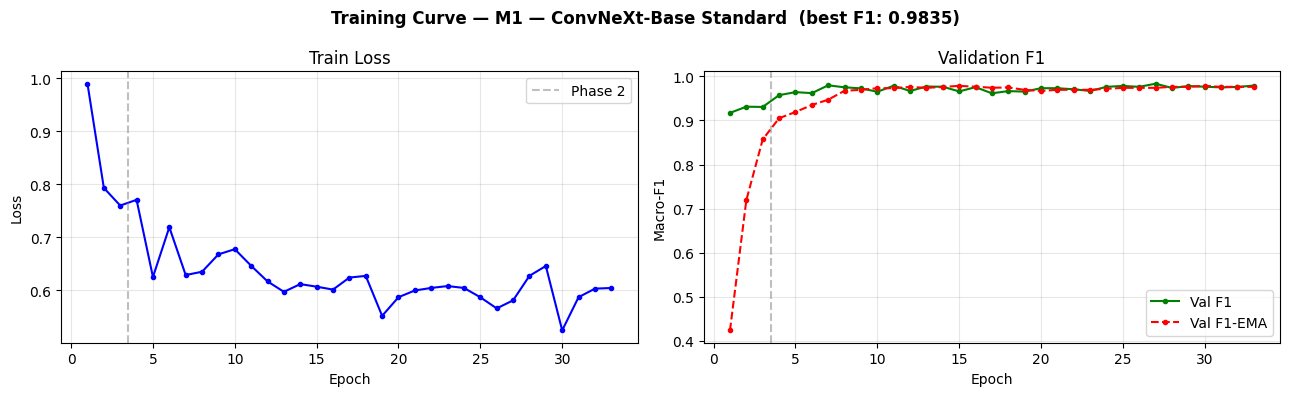

  Peak F1     : 0.9835
  Peak F1-EMA : 0.9786


In [16]:
plot_history(hist_m1, f'M1 — ConvNeXt-Base Standard  (best F1: {best_f1_m1:.4f})')

In [17]:
# M2 — ConvNeXt-Small, resep LLRD
hist_m2, ckpt_m2, best_f1_m2 = train_full(MODEL_CONFIGS[1])


  m2_convnext_small_llrd  |  LLRD  |  drop_path=0.2


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

  convnext_small.fb_in22k_ft_in1k  (49.5M param, drop_path=0.2)

  Phase 1 — head only (3 epoch, LR=0.001)
    Trainable: 0.0054M (head saja)
  Ep 01/3 | loss 1.1320 | F1 0.9134 | F1-EMA 0.4037
  Ep 02/3 | loss 0.8290 | F1 0.9356 | F1-EMA 0.6549
  Ep 03/3 | loss 0.8069 | F1 0.9265 | F1-EMA 0.8407

  Phase 2 — full fine-tune (30 epoch, LLRD)
    LLRD via timm — 76 param groups, decay=0.85
  Ep 01/30 | loss 0.8638 | F1 0.9336 | F1-EMA 0.8872 | best 0.9336 ✓
  Ep 02/30 | loss 0.8152 | F1 0.9349 | F1-EMA 0.9088 | best 0.9349 ✓
  Ep 03/30 | loss 0.7959 | F1 0.9499 | F1-EMA 0.9167 | best 0.9499 ✓
  Ep 04/30 | loss 0.7689 | F1 0.9477 | F1-EMA 0.9284 | best 0.9499
  Ep 05/30 | loss 0.7432 | F1 0.9649 | F1-EMA 0.9338 | best 0.9649 ✓
  Ep 06/30 | loss 0.7258 | F1 0.9636 | F1-EMA 0.9465 | best 0.9649
  Ep 07/30 | loss 0.7129 | F1 0.9613 | F1-EMA 0.9476 | best 0.9649
  Ep 08/30 | loss 0.7131 | F1 0.9659 | F1-EMA 0.9556 | best 0.9659 ✓
  Ep 09/30 | loss 0.7057 | F1 0.9685 | F1-EMA 0.9608 | best 0.9

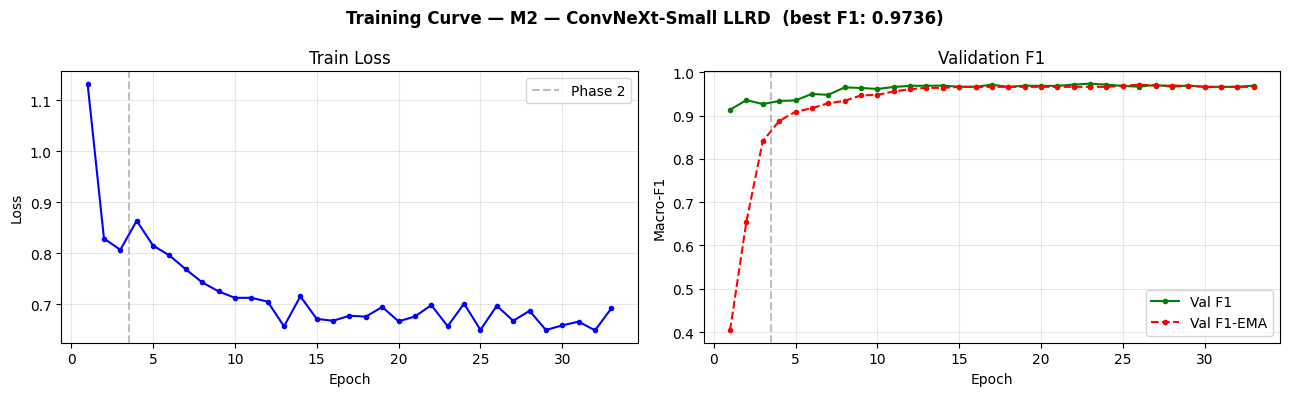

  Peak F1     : 0.9736
  Peak F1-EMA : 0.9713


In [18]:
plot_history(hist_m2, f'M2 — ConvNeXt-Small LLRD  (best F1: {best_f1_m2:.4f})')

In [19]:
# M3 — Swin-Base, resep standar
hist_m3, ckpt_m3, best_f1_m3 = train_full(MODEL_CONFIGS[2])


  m3_swin_base_std  |  Standard  |  drop_path=0.1


model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

  swin_base_patch4_window7_224.ms_in22k_ft_in1k  (86.7M param, drop_path=0.1)

  Phase 1 — head only (3 epoch, LR=0.001)
    Trainable: 0.0051M (head saja)
  Ep 01/3 | loss 1.0232 | F1 0.9168 | F1-EMA 0.3724
  Ep 02/3 | loss 0.8114 | F1 0.9507 | F1-EMA 0.8246
  Ep 03/3 | loss 0.7694 | F1 0.9650 | F1-EMA 0.9093

  Phase 2 — full fine-tune (30 epoch, Standard)
  Ep 01/30 | loss 0.7303 | F1 0.9570 | F1-EMA 0.9266 | best 0.9570 ✓
  Ep 02/30 | loss 0.6651 | F1 0.9499 | F1-EMA 0.9422 | best 0.9570
  Ep 03/30 | loss 0.6512 | F1 0.9575 | F1-EMA 0.9575 | best 0.9575 ✓
  Ep 04/30 | loss 0.6628 | F1 0.9606 | F1-EMA 0.9624 | best 0.9624 ✓
  Ep 05/30 | loss 0.6564 | F1 0.9444 | F1-EMA 0.9696 | best 0.9696 ✓
  Ep 06/30 | loss 0.6406 | F1 0.9637 | F1-EMA 0.9764 | best 0.9764 ✓
  Ep 07/30 | loss 0.6818 | F1 0.9747 | F1-EMA 0.9769 | best 0.9769 ✓
  Ep 08/30 | loss 0.5861 | F1 0.9462 | F1-EMA 0.9769 | best 0.9769 ✓
  Ep 09/30 | loss 0.6432 | F1 0.9761 | F1-EMA 0.9786 | best 0.9786 ✓
  Ep 10/30 | loss 0.

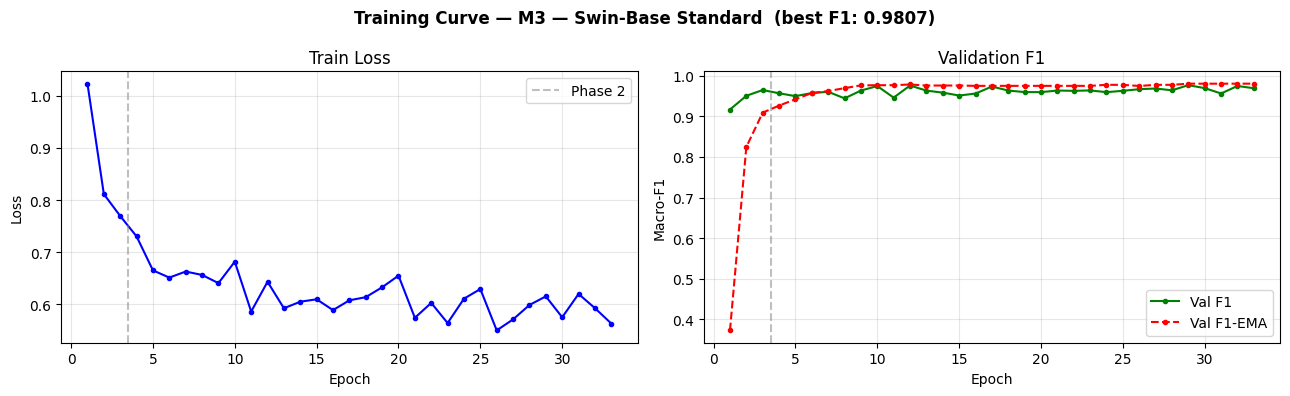

  Peak F1     : 0.9770
  Peak F1-EMA : 0.9807


In [20]:
plot_history(hist_m3, f'M3 — Swin-Base Standard  (best F1: {best_f1_m3:.4f})')

In [21]:
# M4 — Swin-Small, resep LLRD
hist_m4, ckpt_m4, best_f1_m4 = train_full(MODEL_CONFIGS[3])


  m4_swin_small_llrd  |  LLRD  |  drop_path=0.2


model.safetensors: reconstructing file:   0%|          |  0.00B /  200MB            

model.safetensors: downloading bytes:           |  0.00B            

  swin_small_patch4_window7_224.ms_in22k_ft_in1k  (48.8M param, drop_path=0.2)

  Phase 1 — head only (3 epoch, LR=0.001)
    Trainable: 0.0038M (head saja)
  Ep 01/3 | loss 1.0417 | F1 0.9070 | F1-EMA 0.5624
  Ep 02/3 | loss 0.8158 | F1 0.9245 | F1-EMA 0.8544
  Ep 03/3 | loss 0.7680 | F1 0.9322 | F1-EMA 0.9039

  Phase 2 — full fine-tune (30 epoch, LLRD)
    LLRD via timm — 52 param groups, decay=0.85
  Ep 01/30 | loss 0.7986 | F1 0.9377 | F1-EMA 0.9186 | best 0.9377 ✓
  Ep 02/30 | loss 0.6555 | F1 0.9567 | F1-EMA 0.9217 | best 0.9567 ✓
  Ep 03/30 | loss 0.6962 | F1 0.9740 | F1-EMA 0.9267 | best 0.9740 ✓
  Ep 04/30 | loss 0.7340 | F1 0.9603 | F1-EMA 0.9382 | best 0.9740
  Ep 05/30 | loss 0.7023 | F1 0.9663 | F1-EMA 0.9458 | best 0.9740
  Ep 06/30 | loss 0.6895 | F1 0.9661 | F1-EMA 0.9585 | best 0.9740
  Ep 07/30 | loss 0.6857 | F1 0.9690 | F1-EMA 0.9648 | best 0.9740
  Ep 08/30 | loss 0.6585 | F1 0.9738 | F1-EMA 0.9704 | best 0.9740
  Ep 09/30 | loss 0.6359 | F1 0.9738 | F1-EMA 0.9710

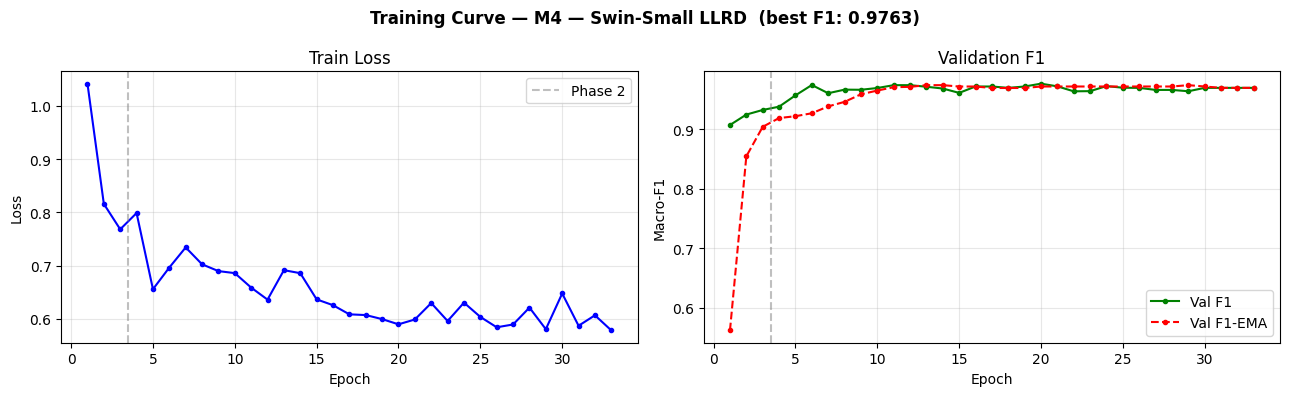

  Peak F1     : 0.9763
  Peak F1-EMA : 0.9738


In [22]:
plot_history(hist_m4, f'M4 — Swin-Small LLRD  (best F1: {best_f1_m4:.4f})')

In [23]:
# Muat checkpoint terbaik semua 4 model
def load_best(cfg, ckpt_path):
    """Muat model dari checkpoint terbaik ke DEVICE dalam mode eval."""
    m = timm.create_model(
        cfg['name'], pretrained=False,
        num_classes=NUM_CLASSES, drop_path_rate=cfg['drop']
    )
    m.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return m.to(DEVICE).eval()


m1 = load_best(MODEL_CONFIGS[0], ckpt_m1)
m2 = load_best(MODEL_CONFIGS[1], ckpt_m2)
m3 = load_best(MODEL_CONFIGS[2], ckpt_m3)
m4 = load_best(MODEL_CONFIGS[3], ckpt_m4)
all_models = [m1, m2, m3, m4]
print('✅ Semua 4 checkpoint dimuat')

✅ Semua 4 checkpoint dimuat


In [24]:
# Performa tiap model secara individual vs baseline NB07
model_labels = [
    'M1 ConvNeXt-Base  Standard',
    'M2 ConvNeXt-Small LLRD   ',
    'M3 Swin-Base      Standard',
    'M4 Swin-Small     LLRD   ',
]
print(f'{"Model":<35} {"Macro-F1":>10} {"Akurasi":>10}')
print('-' * 58)
for lbl, model in zip(model_labels, all_models):
    f1, acc = eval_epoch(model, val_loader)
    print(f'  {lbl:<33} {f1:>10.4f} {acc:>10.4f}')
print('-' * 58)
print(f'  {"Baseline NB07 (2× ConvNeXt-Tiny)":<33} {0.9844:>10.4f}')

Model                                 Macro-F1    Akurasi
----------------------------------------------------------
  M1 ConvNeXt-Base  Standard            0.9835     0.9829
  M2 ConvNeXt-Small LLRD                0.9736     0.9732
  M3 Swin-Base      Standard            0.9807     0.9805
  M4 Swin-Small     LLRD                0.9763     0.9756
----------------------------------------------------------
  Baseline NB07 (2× ConvNeXt-Tiny)      0.9844


In [25]:
# Bandingkan kombinasi ensemble — pilih konfigurasi final terbaik
@torch.no_grad()
def eval_ensemble(models, loader):
    """Ensemble flat-average softmax; kembalikan (f1, acc, preds, truths)."""
    preds, truths = [], []
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        avg  = sum(torch.softmax(m(imgs), dim=1) for m in models) / len(models)
        preds.extend(avg.argmax(1).cpu().tolist())
        truths.extend(labels.tolist())
    f1  = f1_score(truths, preds, average='macro', zero_division=0)
    acc = sum(p == t for p, t in zip(preds, truths)) / len(truths)
    return f1, acc, preds, truths


print('Evaluasi kombinasi ensemble:\n')
print(f'{"Kombinasi":<42} {"Macro-F1":>10} {"Akurasi":>10}')
print('-' * 65)

combos = {}
for name, mdls in [
    ('M1+M2  (2× ConvNeXt)',             [m1, m2]),
    ('M3+M4  (2× Swin)',                 [m3, m4]),
    ('M1+M3  (Base std)',                [m1, m3]),
    ('M2+M4  (Small LLRD)',              [m2, m4]),
    ('M1+M2+M3  (3 model)',              [m1, m2, m3]),
    ('M1+M2+M3+M4  (4 model, semua)',    all_models),
]:
    f1, acc, _, _ = eval_ensemble(mdls, val_loader)
    combos[name]  = (f1, mdls)
    flag = '  ← terbaik' if f1 == max(v[0] for v in combos.values()) else ''
    print(f'  {name:<40} {f1:>10.4f} {acc:>10.4f}{flag}')

print('-' * 65)
best_key            = max(combos, key=lambda k: combos[k][0])
FINAL_F1, FINAL_MODELS = combos[best_key]
print(f'\n✅ Konfigurasi final: {best_key}  →  F1: {FINAL_F1:.4f}')

Evaluasi kombinasi ensemble:

Kombinasi                                    Macro-F1    Akurasi
-----------------------------------------------------------------
  M1+M2  (2× ConvNeXt)                         0.9784     0.9780  ← terbaik
  M3+M4  (2× Swin)                             0.9758     0.9756
  M1+M3  (Base std)                            0.9812     0.9805  ← terbaik
  M2+M4  (Small LLRD)                          0.9710     0.9707
  M1+M2+M3  (3 model)                          0.9787     0.9780
  M1+M2+M3+M4  (4 model, semua)                0.9787     0.9780
-----------------------------------------------------------------

✅ Konfigurasi final: M1+M3  (Base std)  →  F1: 0.9812


  Konfigurasi : M1+M3  (Base std)
  Macro-F1    : 0.9812   (baseline NB07: 0.9844)
  Akurasi     : 0.9805
  Delta F1    : -0.0032

               precision    recall  f1-score   support

botol_plastik       0.99      0.97      0.98        78
gelas_plastik       0.95      1.00      0.97        78
kertas_kardus       0.98      1.00      0.99        54
saset_kemasan       0.98      0.96      0.97       100
    styrofoam       1.00      0.98      0.99       100

     accuracy                           0.98       410
    macro avg       0.98      0.98      0.98       410
 weighted avg       0.98      0.98      0.98       410



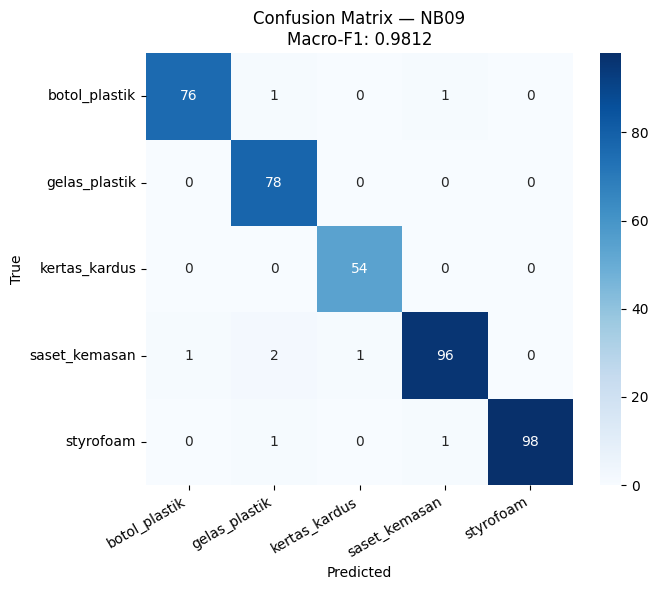

In [26]:
# Evaluasi final — classification report dan confusion matrix
f1_fin, acc_fin, final_preds, final_truths = eval_ensemble(FINAL_MODELS, val_loader)

print('=' * 55)
print(f'  Konfigurasi : {best_key}')
print(f'  Macro-F1    : {f1_fin:.4f}   (baseline NB07: 0.9844)')
print(f'  Akurasi     : {acc_fin:.4f}')
print(f'  Delta F1    : {f1_fin - 0.9844:+.4f}')
print('=' * 55)
print()
print(classification_report(final_truths, final_preds, target_names=CLASSES))

cm = confusion_matrix(final_truths, final_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix — NB09\nMacro-F1: {f1_fin:.4f}')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

In [27]:
# Simpan ensemble sebagai state_dict fp16

class Ensemble(nn.Module):
    """Flat-average ensemble — output log(avg softmax) [batch, 5]."""
    def __init__(self, members):
        super().__init__()
        self.members = nn.ModuleList(members)

    def forward(self, x):
        avg = torch.stack([torch.softmax(m(x), dim=1) for m in self.members]).mean(0)
        return torch.log(avg + 1e-8)


ensemble_save = Ensemble(FINAL_MODELS).eval().cpu()
state_fp16    = {k: v.half() if v.is_floating_point() else v
                 for k, v in ensemble_save.state_dict().items()}

PTH_PATH = os.path.join(SUBMISSION_DIR, 'model.pth')
torch.save(state_fp16, PTH_PATH)

print(f'✅ model.pth tersimpan → {PTH_PATH}')
print(f'   Ukuran  : {os.path.getsize(PTH_PATH) / 1e6:.1f} MB (fp16)')
print(f'   N model : {len(FINAL_MODELS)}')

✅ model.pth tersimpan → /content/submission_nb09/model.pth
   Ukuran  : 348.8 MB (fp16)
   N model : 2


In [28]:
# Generate model.py — kompatibel dengan evaluate.py dosen
id_to_cfg    = {id(m): cfg for m, cfg in zip(all_models, MODEL_CONFIGS)}
member_names = [id_to_cfg[id(m)]['name'] for m in FINAL_MODELS]
member_drops = [id_to_cfg[id(m)]['drop'] for m in FINAL_MODELS]

lines = [
    '"""',
    'model.py — Submission NB09',
    f'Ensemble {len(member_names)} model:',
] + [
    f'  {i+1}. {n}  drop_path={d}'
    for i, (n, d) in enumerate(zip(member_names, member_drops))
] + [
    'Urutan kelas (alfabetis ImageFolder):',
    '  0 botol_plastik  1 gelas_plastik  2 kertas_kardus  3 saset_kemasan  4 styrofoam',
    '"""',
    '',
    'import torch',
    'import torch.nn as nn',
    'from torchvision import transforms',
    'import timm',
    '',
    'NUM_CLASSES   = 5',
    'IMG_SIZE      = 224',
    'RESIZE_SIZE   = 256',
    'IMAGENET_MEAN = [0.485, 0.456, 0.406]',
    'IMAGENET_STD  = [0.229, 0.224, 0.225]',
    '',
    f'MEMBER_NAMES = {member_names}',
    f'MEMBER_DROPS = {member_drops}',
    '',
    '',
    'class Ensemble(nn.Module):',
    '    """Flat-average ensemble: rata-rata softmax semua anggota."""',
    '',
    '    def __init__(self, num_classes=NUM_CLASSES):',
    '        super().__init__()',
    '        self.members = nn.ModuleList([',
    '            timm.create_model(name, pretrained=False,',
    '                              num_classes=num_classes, drop_path_rate=dp)',
    '            for name, dp in zip(MEMBER_NAMES, MEMBER_DROPS)',
    '        ])',
    '',
    '    def forward(self, x):',
    '        avg = torch.stack([torch.softmax(m(x), dim=1) for m in self.members]).mean(0)',
    '        return torch.log(avg + 1e-8)',
    '',
    '',
    'def get_model():',
    '    """Bangun arsitektur ensemble — bobot dimuat dari model.pth oleh evaluate.py."""',
    '    return Ensemble(num_classes=NUM_CLASSES)',
    '',
    '',
    'def get_transform():',
    '    """Transform inferensi: Resize(256) + CenterCrop(224) + normalisasi ImageNet."""',
    '    return transforms.Compose([',
    '        transforms.Resize(RESIZE_SIZE),',
    '        transforms.CenterCrop(IMG_SIZE),',
    '        transforms.ToTensor(),',
    '        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),',
    '    ])',
]

PY_PATH  = os.path.join(SUBMISSION_DIR, 'model.py')
model_py = '\n'.join(lines) + '\n'
with open(PY_PATH, 'w') as f:
    f.write(model_py)
print(f'✅ model.py tersimpan → {PY_PATH}\n')
print('--- Isi model.py ---')
print(model_py)

✅ model.py tersimpan → /content/submission_nb09/model.py

--- Isi model.py ---
"""
model.py — Submission NB09
Ensemble 2 model:
  1. convnext_base.fb_in22k_ft_in1k  drop_path=0.1
  2. swin_base_patch4_window7_224.ms_in22k_ft_in1k  drop_path=0.1
Urutan kelas (alfabetis ImageFolder):
  0 botol_plastik  1 gelas_plastik  2 kertas_kardus  3 saset_kemasan  4 styrofoam
"""

import torch
import torch.nn as nn
from torchvision import transforms
import timm

NUM_CLASSES   = 5
IMG_SIZE      = 224
RESIZE_SIZE   = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

MEMBER_NAMES = ['convnext_base.fb_in22k_ft_in1k', 'swin_base_patch4_window7_224.ms_in22k_ft_in1k']
MEMBER_DROPS = [0.1, 0.1]


class Ensemble(nn.Module):
    """Flat-average ensemble: rata-rata softmax semua anggota."""

    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.members = nn.ModuleList([
            timm.create_model(name, pretrained=False,
                      

In [29]:
# Simpan requirements.txt, verifikasi, dan backup ke Drive

# requirements.txt
REQ_PATH = os.path.join(SUBMISSION_DIR, 'requirements.txt')
with open(REQ_PATH, 'w') as f:
    f.write('timm\n')
print(f'✅ requirements.txt tersimpan  (isi: timm)\n')

# Verifikasi — simulasi evaluate.py dosen
print('Verifikasi submission (simulasi evaluate.py) ...')
spec    = importlib.util.spec_from_file_location('model_sub', PY_PATH)
mod     = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

model_v = mod.get_model()
state_v = torch.load(PTH_PATH, map_location='cpu')
state_v = {k: v.float() if v.is_floating_point() else v for k, v in state_v.items()}
model_v.load_state_dict(state_v)
model_v = model_v.to(DEVICE).eval()
_       = mod.get_transform()

imgs_t, _ = next(iter(val_loader))
with torch.no_grad():
    out = model_v(imgs_t.to(DEVICE))
print(f'  Output shape    : {tuple(out.shape)}  ← harus (batch, 5)')

f1_v, acc_v = eval_epoch(model_v, val_loader)
print(f'  Macro-F1 verify : {f1_v:.4f}')
print(f'  Akurasi verify  : {acc_v:.4f}')
print('  ✅ Submission valid — siap dipakai evaluate.py\n')

# Backup ke Drive
DRIVE_SUB = os.path.join(DRIVE_ROOT, 'submission_nb09')
if os.path.isdir(DRIVE_SUB):
    shutil.rmtree(DRIVE_SUB)
shutil.copytree(SUBMISSION_DIR, DRIVE_SUB)
print(f'✅ Backup ke Drive → {DRIVE_SUB}')
for fname in sorted(os.listdir(DRIVE_SUB)):
    sz = os.path.getsize(os.path.join(DRIVE_SUB, fname))
    print(f'   {fname:<25} {sz / 1e6:>8.2f} MB')

✅ requirements.txt tersimpan  (isi: timm)

Verifikasi submission (simulasi evaluate.py) ...
  Output shape    : (32, 5)  ← harus (batch, 5)
  Macro-F1 verify : 0.9812
  Akurasi verify  : 0.9805
  ✅ Submission valid — siap dipakai evaluate.py

✅ Backup ke Drive → /content/drive/MyDrive/submission_nb09
   __pycache__                   0.00 MB
   model.pth                   348.81 MB
   model.py                      0.00 MB
   requirements.txt              0.00 MB


In [30]:
# Ringkasan akhir
print('=' * 60)
print('  RINGKASAN NB09')
print('=' * 60)
print(f'  Baseline NB07   : 0.9844  (2× ConvNeXt-Tiny)')
print(f'  NB09 final      : {f1_fin:.4f}')
print(f'  Delta           : {f1_fin - 0.9844:+.4f}')
print()
print('  Model dalam ensemble:')
for i, (m, cfg) in enumerate(zip(FINAL_MODELS, MODEL_CONFIGS)):
    resep = 'LLRD' if cfg['llrd'] else 'Standard'
    print(f'    {i+1}. {cfg["name"]}  [{resep}]')
print()
print('  Deliverable (Drive/submission_nb09/):')
for fname in sorted(os.listdir(DRIVE_SUB)):
    sz = os.path.getsize(os.path.join(DRIVE_SUB, fname))
    print(f'    {fname:<28} {sz / 1e6:>6.1f} MB')
print()
status = 'SUBMIT ✅' if f1_fin > 0.9844 else 'TETAP NB07 ⚠️'
print(f'  Keputusan          : {status}')
print('=' * 60)

  RINGKASAN NB09
  Baseline NB07   : 0.9844  (2× ConvNeXt-Tiny)
  NB09 final      : 0.9812
  Delta           : -0.0032

  Model dalam ensemble:
    1. convnext_base.fb_in22k_ft_in1k  [Standard]
    2. convnext_small.fb_in22k_ft_in1k  [LLRD]

  Deliverable (Drive/submission_nb09/):
    __pycache__                     0.0 MB
    model.pth                     348.8 MB
    model.py                        0.0 MB
    requirements.txt                0.0 MB

  Keputusan          : TETAP NB07 ⚠️
